# E99: Does the net share at a located head pair read the right answer when the answer is known?

**The answer.** On the copying pair, the net share works as the definition needs. A fine-tune forced through the pair reads all of its gain there, and one trained with the pair switched off reads none, inside its random band. On the lowercase pair it does not. The forced fine-tune reads all its gain there but reaches only about two thirds of the native gain, so the filed fallback applies and lowercase stays "does not apply". The forbidden lowercase fine-tune read far below its band, against the filed expectation.

*Status: provisional, no independent check. Full record: `reports/analyses/2026-11-05_analysis_e99-definition-verify.md`. A new circuit built from old parts still reads as reuse, on every claim below.*


## What we were trying to test

Our definition of reuse says an update reuses a capability when its behaviour runs through what that capability computes, read by removing it. Since the user's decision of 2026-11-05, a label needs a located mechanism. E97 located two pairs of attention heads in the 67M model: heads (2,3) and (2,4) carry the copy fine-tune's gain, and heads (1,1) and (1,2) matter on the lowercase task.

Fable proposed reading a located pair through the **net share**. Switch the pair off, by setting its outputs to the original model's mean over the same inputs, in both the fine-tuned model and the original model. Then

$$\text{net} = \frac{\text{fine-tune's drop} - \text{original model's drop}}{G},$$

where $G$ is the fine-tune's mean gain in the log-odds of its target. A net share of 1 means the whole gain vanishes with the pair, 0 means none of it does, and a negative value means the gain is larger with the pair off. Each state's **band** is the 95th percentile of the absolute net share over 20 random head pairs outside the pair.

To test the quantity we need fine-tunes whose answer is known by construction:

- **Forced**: only the pair's query, key and value weights may move; everything else is reset to the original model after every step. Switching the pair off then leaves exactly the original model with the pair off, so the net share must be 1. This is the positive control.
- **Forbidden**: train with the pair held at its mean and its weights frozen, then read with the pair restored. The update never used the pair, so the net share should sit inside the band.

Each arm trains until its gain, read on a check subset in its training condition, is within 2% of the native fine-tune's, capped at ten times the native's steps. Copy uses E62's recipe and windows, 30 native steps, with E62's lookup fine-tune as the control that should be spared. Lowercase uses E53's recipe on whole rows, 300 native steps, with E53's cipher fine-tune as its control. Two seeds each.

A first stage checks the apparatus: the original model's drops must reproduce E97's. It also tests a proposed admissibility clause: the lowercase pair must change the original model's case leaning on cased rows, which the lowercase task never trained on.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/definition_verify/figures")


## What we expected, and why

The first stage should reproduce E97 to the digit, since the code and inputs are the same, and the lookup fine-tune should lose nothing at the copying pair. The lowercase pair was expected to move the case leaning on cased rows; the coded rule also asked for a move on lowercased rows, which the plan did not.

Both forced arms should read 1 within 0.05, whether or not they reach the native gain. The filing says what failing to reach it means on lowercase: the net share then has no positive control there, and lowercase falls back to "does not apply". Both forbidden arms should read inside their band. On copy the gain with the pair restored should be within 10% of the native's; on lowercase the arm should learn as fast as the native.

## What we observed

### Does the lowercase pair change the original model's case leaning on text it was never trained on?


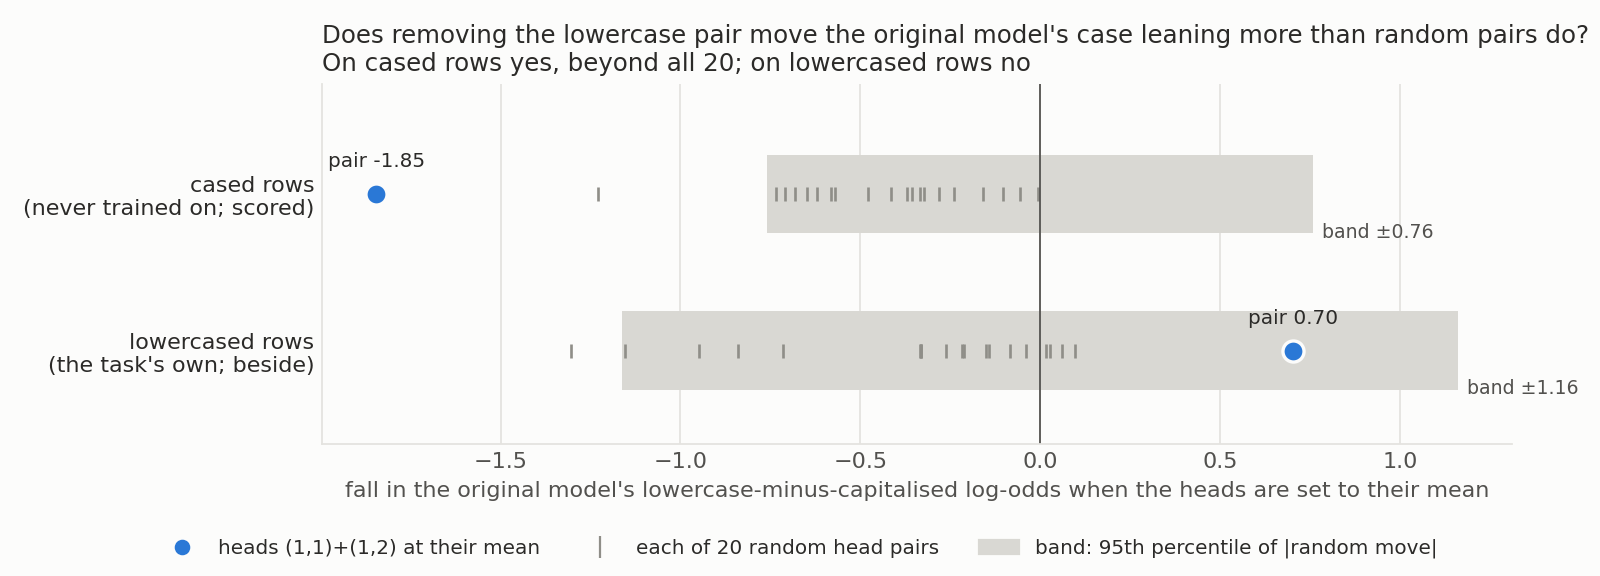

In [2]:
display(Image(FIG / "clause_ii.png", width=950))


**Reading it.** On cased rows yes; on lowercased rows it cannot be told from random pairs. Switching the pair off moves the case leaning on cased rows by -1.85, beyond the band of 0.76 and beyond every random pair. On lowercased rows it moves by 0.70, inside a band of 1.16. The coded rule asked for both, so it missed and the lowercase arms were skipped. Amendment 1, filed before running, scored the plan's wording, cased rows only; that passed, and the lowercase arms ran in a second job. The caveat: every random pair also moves the cased-row leaning in the same direction. The clause shows the pair matters more than a random pair to this one gap, not that it does something specific to case.

### How much of each fine-tune's gain disappears with the pair off?


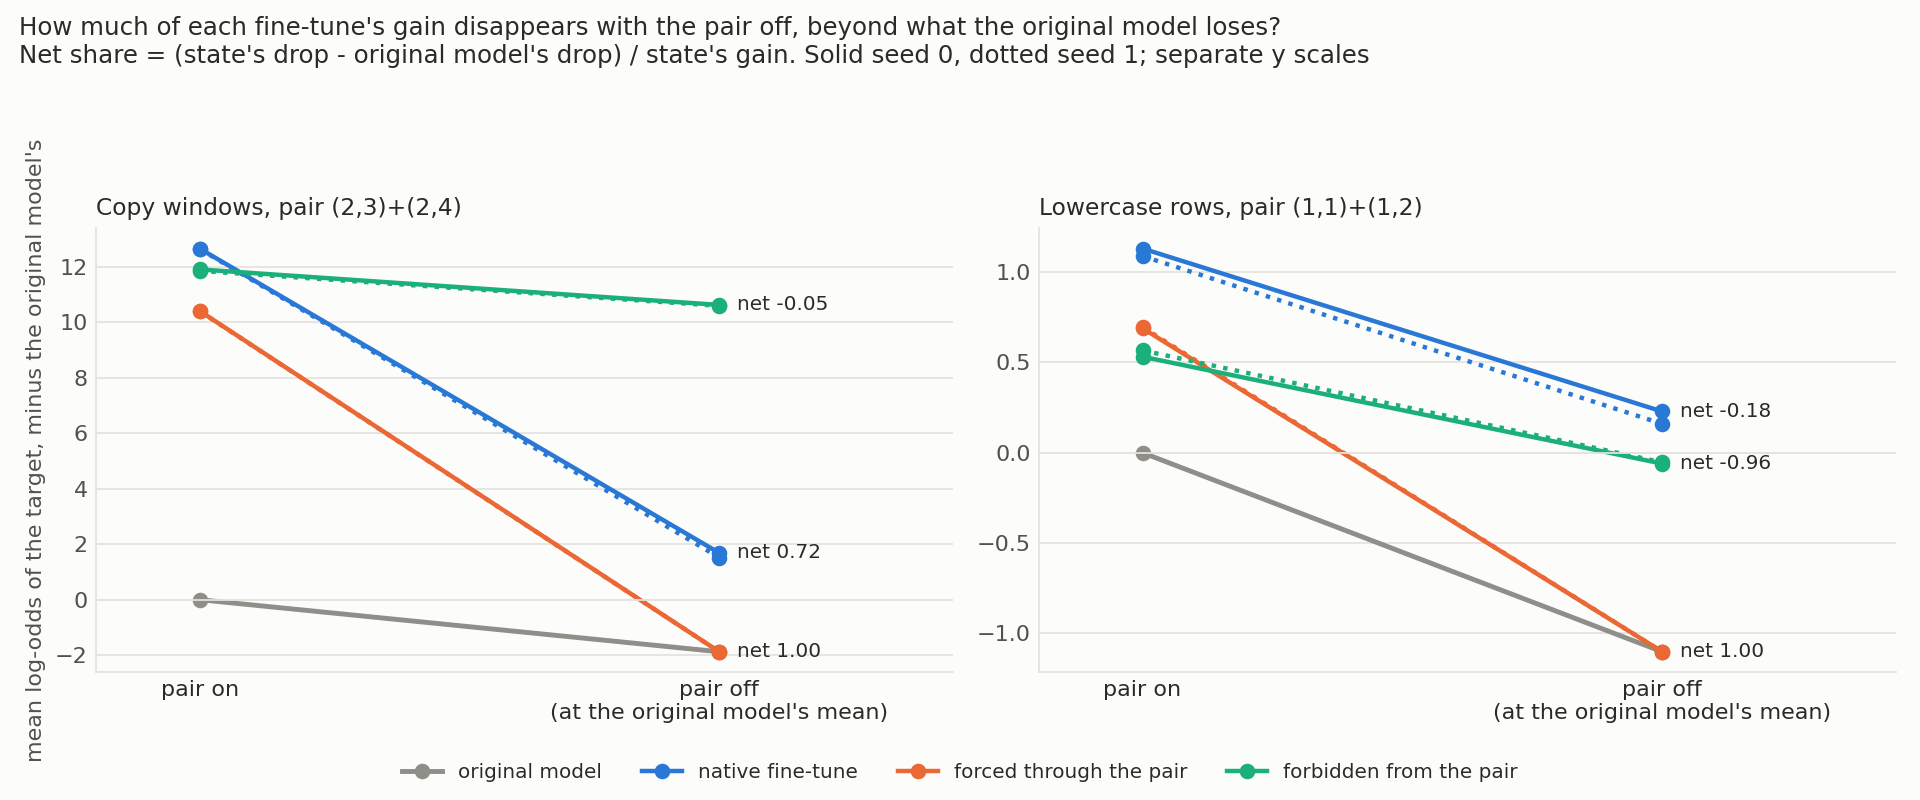

In [3]:
display(Image(FIG / "on_off.png", width=1000))


**Reading it.** On copy the three fine-tunes separate cleanly. The forced fine-tune falls to exactly where the original model falls, net 1. The native falls most of the way, net 0.72. The forbidden fine-tune barely moves, net -0.05. On lowercase the forced fine-tune also lands on the original model, net 1, but it started only 0.69 above it, against the native's 1.13. The forbidden lowercase fine-tune's line is the anomaly: with the pair on it sits 0.53 above the original model, and with the pair off 0.06 below it.

### Do the forced and forbidden fine-tunes read 1 and about 0, against each state's band?


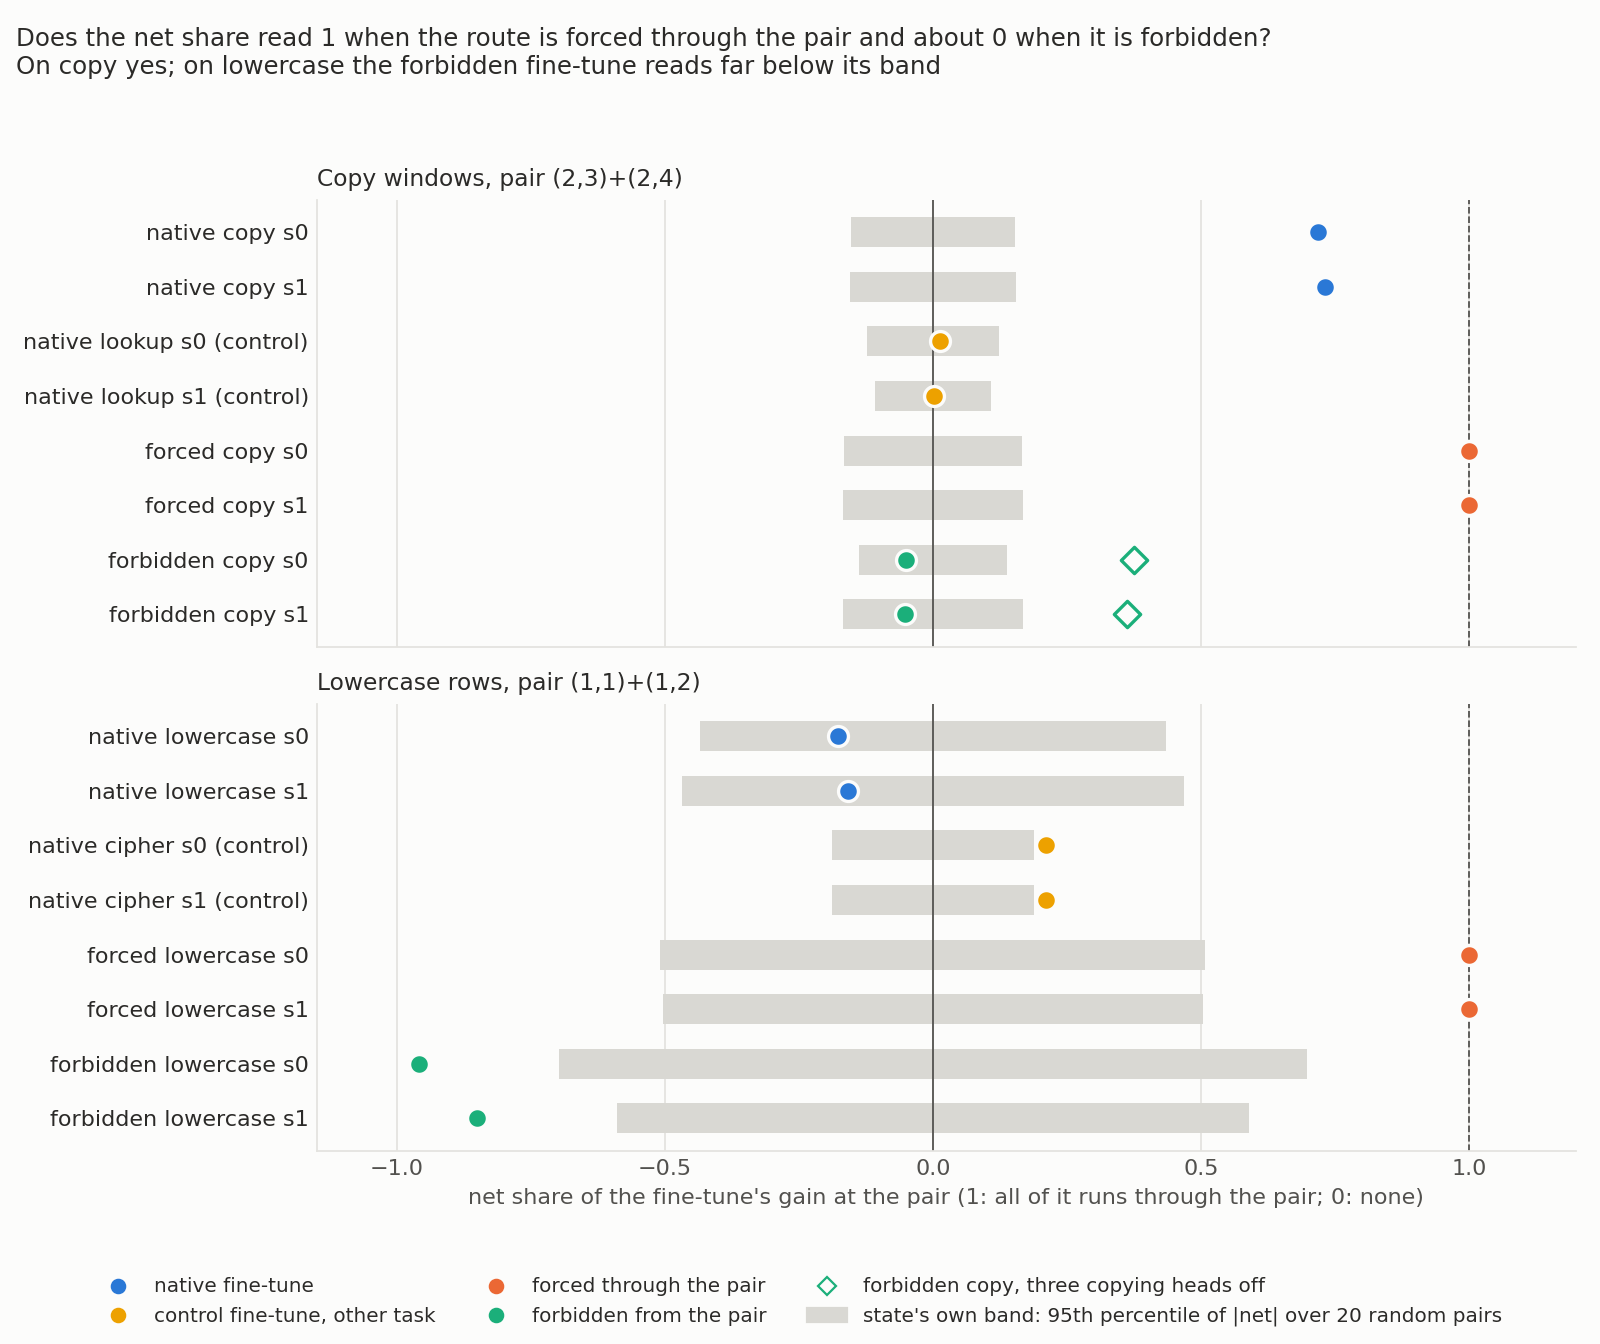

In [4]:
display(Image(FIG / "net_share.png", width=900))


**Reading it.** On copy yes, on both seeds; on lowercase only the forced half does. Forced reads 1.00 on both tasks. Forbidden copy reads -0.05 against bands of 0.14 and 0.17, and keeps 0.94 of the native gain with the pair restored. With head (3,4) also off, the third copying head E62 found, forbidden copy loses about 0.37 net: part of its route moved to a neighbouring copying head. No band was drawn for that set, so it is a reading beside. Forbidden lowercase reads -0.96 and -0.85, far below bands of 0.70 and 0.59. The cipher control at the lowercase pair reads 0.21 net, just above its band of 0.19.

### Why does forbidden lowercase read far below its band?

The figure of each model with the pair on and off shows it. The arm's stop rule compared its gain, read with the pair off and against the original model with the pair off, to the native's gain, read against the intact original model. On lowercase, switching the pair off costs the original model 1.10, about the whole target of 1.15. After five steps the arm had made up that cost: with the pair off it sits 0.06 below the intact original model, and the check read past the target, so training stopped. The training loss on the same first batch shows the deficit it started from: 4.05 with the pair off against 3.31 with it on. On copy the same cost is 1.88 against a target of 12.6, so the forbidden copy arm was barely affected.

The restored model is not worse than the ablated one; putting the pair back raises it by 0.59. That is about half of what the pair gives the original model, 1.10. So the update raises the target by 1.04 with the pair off in both models, and by only 0.53 with it on. That is what a net share of -0.96 says: what the update adds does not stack on top of what the pair does. Why not is unmeasured, and whether an arm trained to the native gain would also read below band was not run.

### Can a fine-tune reach the native gain through the pair alone?


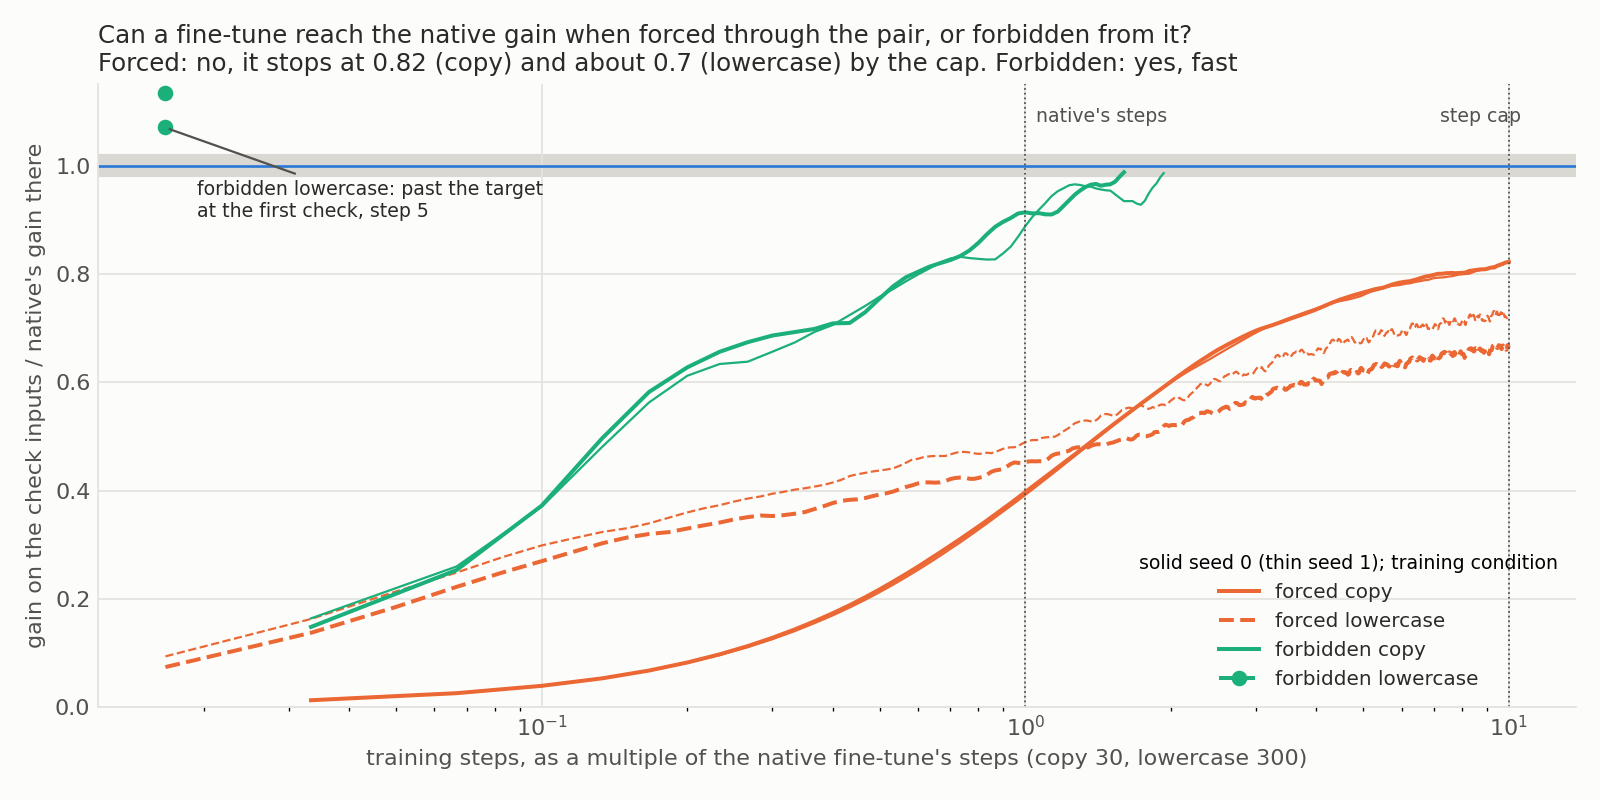

In [5]:
display(Image(FIG / "gain_curves.png", width=950))


**Reading it.** No, on either task. Limited to the two heads' query, key and value weights, the copy fine-tune reaches 0.82 of the native gain by the cap of 300 steps, still rising slowly. The lowercase fine-tune reaches 0.61 and 0.64 on whole rows by 3,000 steps, its curve nearly flat. On copy this does not touch the filed rule. On lowercase the filing reads it as no positive control, and lowercase stays "does not apply". The forbidden copy arm reaches the native gain in 48 and 58 steps.


## What we learned

The net share passes both of its tests on the copying pair, so the copy-against-lookup pair can carry a verdict rather than an assumption, with the granularity limit beside it. On the lowercase pair the forced fine-tune cannot reach the native gain, so the quantity has no positive control there. Fixed-answer tasks stay "does not apply", as the plan said they would in that case. The user's batch decision of 2026-11-05 holds as it stands: only the copying pair qualifies for a label. E99 adds a measured reason why the tasks we called strengthening still have no reading of "existing".

## How compelling is the evidence

Two seeds per arm, one copy task, one lowercase task, one model; the seeds agree closely except the forbidden lowercase net share, -0.96 against -0.85. Each band comes from one draw of 20 random pairs, so it is about as uncertain as its largest draw. The net share cannot see a new function built inside the pair, which reads as "through the pair", or rerouting through other copying heads, which reads as "not through". The forced arm's 1 is true by construction: it shows the code reads the construction, not that a natural fine-tune would read 1.

## Surprises

- **Something we did not predict: the forbidden lowercase fine-tune reads far below its band**, where within band was filed. The stop rule ended its training at step 5, with half the native gain once the pair is restored.
- Both forced arms stop short of the native gain.
- On cased rows every random pair moves the case leaning in the same direction as the lowercase pair.
- Forbidden copy partly moved to head (3,4), as Fable warned it might.

## What next

1. **Stage 4**: the old tasks under the refined rules. It adds the copy verdict with its positive control, the copy maps closed by the admissibility rule with E95's token reader as the reason, and per-state bands on every old row. It also rebuilds the class map and its shuffled twin and reads them with the hand-write control. That is the one old task whose capability is neither its answer nor its input token.
2. If a lowercase reading is still wanted, a forbidden arm stopped against the intact original model would say whether the below-band reading survives at the native gain. It would still not give the net share a positive control on lowercase.
3. The rule changes go to the user in one batch, as planned.


## Scorecard

| Id | Claim | Rule | Read | Verdict |
|---|---|---|---|---|
| S0 | Controls reproduce E97; lookup spared | E97 within row SE; lookup net at most 0.2 | exact; 0.014, 0.003 | held |
| S0-ii | Pair moves case gap on cased and lowercased rows | above band on both | -1.85 vs 0.76; 0.70 vs 1.16 | missed as coded |
| S0-ii-A1 | Same, cased rows only | above band | -1.85 vs 0.76 | held |
| P1 | Forced copy net 1 | within 0.05 | 1.00, 1.00; cap 0.82 | held |
| P2 | Forbidden copy within band; restored within 10% | band; 10% | -0.05, -0.05; 0.94 | held |
| P3 | Forced lowercase net 1, matched or cap | within 0.05 | 1.00, 1.00; cap 0.61, 0.64 | held; cap: falls back to "does not apply" |
| P4 | Forbidden lowercase within band, as fast | band; pace | -0.96, -0.85; step 5 | missed: below band; pace held |

## Not run

- Stage 4: the old tasks under the refined rules, the class map and its twin rebuilt, the one table.
- The hand-write control the plan's design check names; the stage 0-3 code left it out.
- Forced-part lookup, the optional arm that would put a number on the granularity limit.
- A second set of random pairs for the band.
- A forbidden lowercase arm trained to the native gain against the intact original model.
- A band for the three-head copying set; any repurposing read on forced lowercase; an independent check; more seeds.

## Departures from the literature

- Jain et al. 2024 read possession through a linear readout and test reuse with probing, pruning and reverse fine-tuning; we read reuse by ablating a located head pair, as the user decided.
- The net share subtracts the original model's own drop; neither Jain et al. nor E97 does.
- Ablation means come from the site's own inputs, as in E96 and E97, not from a separate reference distribution.
- Ground truth comes from restricting a real fine-tune's update, not from compiled or synthetic-grammar models.
- Recipe: lowercase rows repeat past 300 steps; the gradient clip counts reset entries; forbidden arms train with the pair at its mean.

## Provenance

Results `experiments/definition_verify/results/stage{0,1,2}.json`, `stage3_amend1.json`, `run.out`. Jobs 52787 (stages 0-2, 296 s) and 52807 (Amendment 1 and stage 3, 704 s), MATS `debug`, L40, $0.
